# Parte 2 – Recorte en realizaciones y artefactos

Épocas de 2 s dentro de cada bloque (y de cada pausa), criterios de rechazo (saturación, pico a pico, varianza, curtosis, señal plana) con umbrales justificados por sus distribuciones, un criterio a nivel canal para los picos angostos dentro de beta, y la calidad de señal resultante por sujeto, canal y condición.

Cadena por sesión (ver `epocas.epocas_sujeto`):
1. Se marcan las muestras saturadas sobre la señal **cruda** y la máscara se ensancha 1 s para cada lado.
2. `filtrado.filtrar`: LMS (μ = 3·10⁻³) + pasa banda Butterworth con `filtfilt` (Parte 1).
3. Cada bloque y cada pausa se recorta en épocas de 2 s; se calculan los criterios por época y canal.

El detalle se muestra sobre **B1** y los umbrales se eligen con los **20 sujetos**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, integrate

from eeg_nback import datos, filtrado, epocas
from eeg_nback.config import load_config

cfg = load_config()
FS = cfg['FS']
CANALES = cfg['CANALES']
F_LINEA = cfg['F_LINEA']
BANDAS = cfg['BANDAS']
MU = 3e-3                                              # Parte 1, sección 2.2
SOS = filtrado.disenar_pasabanda(FS)                    # 1-40 Hz (Parte 1)
SOS_BETA = filtrado.disenar_pasabanda(FS, 13, 40)       # versión para beta (sección 3)
DUR = 2.0

## 1. Recorte en épocas

**Por qué 2 s:**
- Los estímulos se presentan cada 2 s (500 ms de estímulo + 1500 ms de cruz de fijación). Las épocas empiezan en el primer estímulo de cada bloque, así que cada época contiene **un ensayo completo** y todas las épocas de la tarea tienen la misma estructura.
- Dentro de un bloque (unos 43 s) el EEG se puede tratar como estacionario en sentido amplio: cada época es una realización del mismo proceso. Un bloque da 21 épocas y una pausa (unos 15 s), 7.
- Con una ventana de 2 s la resolución espectral es 1/2 s = 0,5 Hz: alcanza para bandas de 3 Hz o más de ancho (delta es la más angosta).
- Épocas más largas tienen más probabilidad de contener un artefacto: con 4 s se descartaría el doble de señal por cada parpadeo.

Además de los bloques se recortan las **pausas** entre bloques (desde el fin de un bloque hasta el primer estímulo del siguiente) con `tipo = "pausa"`: sirven de referencia de reposo para la Parte 3.

In [3]:
sujetos = datos.listar_sujetos()
s = sujetos.query("sujeto == 'B1'").iloc[0]

ep_b1, info_b1, cs_b1 = epocas.epocas_sujeto(s.ruta, FS, CANALES, SOS, F_LINEA, MU, DUR)
print(f"{s.sujeto}: {ep_b1.shape[0]} épocas de {ep_b1.shape[1]} muestras ({DUR:g} s) × {ep_b1.shape[2]} canales")
info_b1.groupby(['condicion', 'tipo'], sort=False).size().unstack()

B1: 1322 épocas de 512 muestras (2 s) × 4 canales


tipo,1-back,pausa,3-back
condicion,,,
basal,166,106,166
perfume,167,107,168
cafe,168,106,168


## 2. Primera mirada: B1

Criterios por época y canal (`epocas.criterios`) sobre la señal filtrada de 1–40 Hz. La curtosis es la de Pearson: vale 3 para una gaussiana, más de 3 si hay eventos aislados grandes (colas pesadas) y menos de 3 si la señal es casi una senoidal (1,5 para una senoidal pura).

In [4]:
tab_b1 = epocas.tabla_criterios(ep_b1, info_b1, CANALES)
tab_b1.groupby('canal', sort=False)[['pico_a_pico', 'desvio', 'curtosis']].median().round(1)

,pico_a_pico,desvio,curtosis
canal,,,
TP9,327.8,47.2,9.2
AF7,380.8,81.1,2.2
AF8,61.8,10.4,3.1
TP10,318.7,46.3,10.1


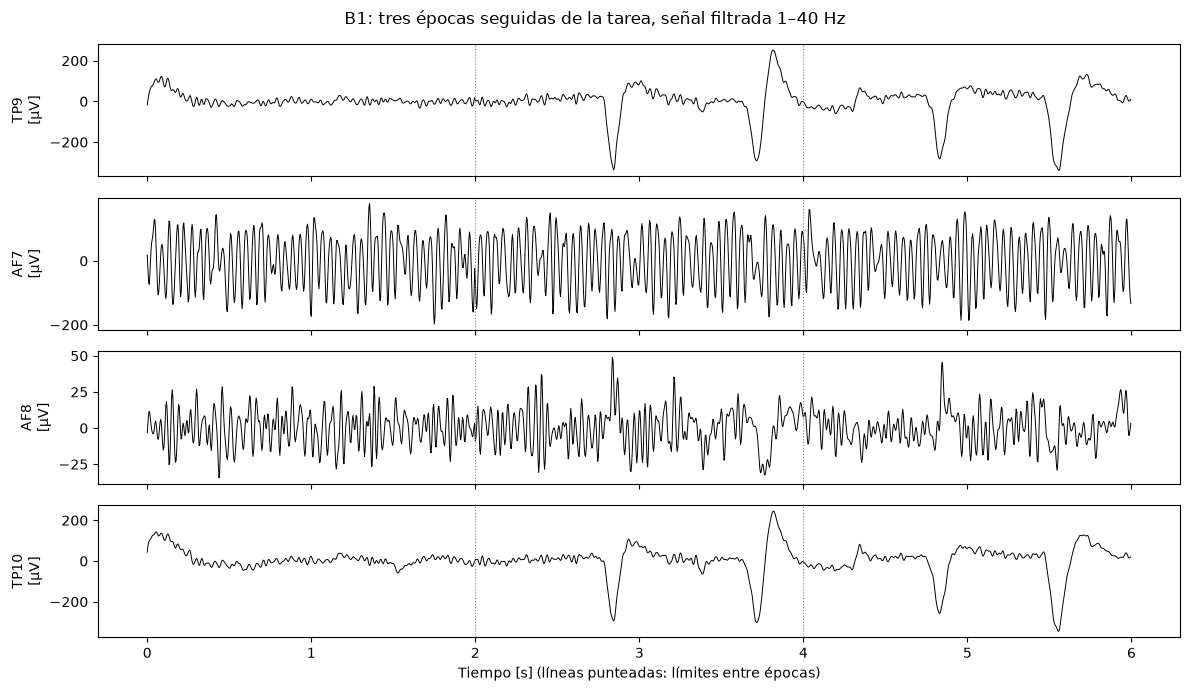

In [5]:
k = info_b1.index[info_b1.tipo != 'pausa'][40]
tt = np.arange(3 * ep_b1.shape[1]) / FS
fig, axs = plt.subplots(len(CANALES), 1, sharex=True, figsize=(12, 7))
for ax, (j, c) in zip(axs, enumerate(CANALES)):
    ax.plot(tt, np.concatenate(ep_b1[k:k + 3, :, j]), lw=0.7, color='k')
    for b in (2, 4):
        ax.axvline(b, color='gray', ls=':', lw=0.8)
    ax.set_ylabel(f'{c}\n[µV]')
axs[-1].set_xlabel('Tiempo [s] (líneas punteadas: límites entre épocas)')
fig.suptitle(f'{s.sujeto}: tres épocas seguidas de la tarea, señal filtrada 1–40 Hz')
plt.tight_layout()

Se ven dos problemas que los criterios planteados no resuelven bien:

1. **TP9 y TP10: deflexiones negativas de unos 300 µV, simultáneas en los dos canales**, una o dos por época. Por eso la curtosis mediana de esos canales es ~10. No están sincronizadas con los estímulos (sección 2.1). Son compatibles con **parpadeos vistos a través de la referencia**: los cuatro canales se miden respecto de Fpz, en la frente. AF7 y AF8 están al lado de la referencia y el potencial del parpadeo casi se cancela; TP9 y TP10 están lejos y lo ven entero, con el signo invertido (canal − referencia).
2. **AF7: una oscilación casi senoidal** de ~150 µV, que es el pico angosto de 21,3 Hz de la Parte 1. Como es casi una senoidal, su curtosis es baja (~2) y el criterio de curtosis no la detecta, pero domina el canal.

### 2.1 Las deflexiones de TP9/TP10 no están ligadas al estímulo, y no afectan a beta

Promedio de todas las épocas de tarea (alineadas con el estímulo): si las deflexiones fueran una respuesta al estímulo o al botón, aparecerían en el promedio.

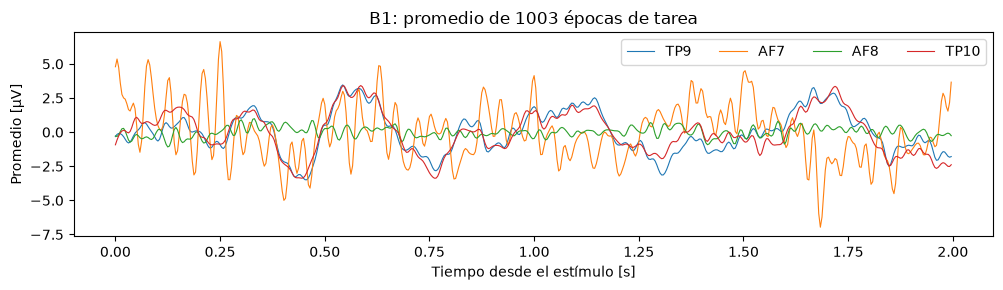

In [6]:
tarea = (info_b1.tipo != 'pausa').to_numpy()
prom = ep_b1[tarea].mean(axis=0)
fig, ax = plt.subplots(figsize=(10, 3))
for j, c in enumerate(CANALES):
    ax.plot(np.arange(ep_b1.shape[1]) / FS, prom[:, j] - prom[:, j].mean(), lw=0.8, label=c)
ax.set_xlabel('Tiempo desde el estímulo [s]')
ax.set_ylabel('Promedio [µV]')
ax.set_title(f'{s.sujeto}: promedio de {tarea.sum()} épocas de tarea')
ax.legend(ncol=4)
plt.tight_layout()

El promedio queda en unos pocos µV, contra deflexiones de ~300 µV en cada época: no están sincronizadas con el estímulo.

Se detectan como un mínimo de la media de TP9 y TP10 más de 100 µV por debajo de la mediana de la época, y se compara la potencia de cada banda en las épocas con y sin deflexión:

In [7]:
def pot_bandas(ep):
    f, p = signal.welch(ep, FS, nperseg=ep.shape[1], axis=1)
    return {b: integrate.trapezoid(p[:, (f >= lo) & (f < hi)], f[(f >= lo) & (f < hi)], axis=1)
            for b, (lo, hi) in BANDAS.items()}

tp = (ep_b1[:, :, CANALES.index('TP9')] + ep_b1[:, :, CANALES.index('TP10')]) / 2
con_deflexion = (tp.min(axis=1) - np.median(tp, axis=1)) < -100
print(f"Épocas con deflexión en TP9/TP10: {con_deflexion.mean() * 100:.0f} % ({con_deflexion.sum()} de {len(tp)})")

P = pot_bandas(ep_b1)
pd.DataFrame({b: [np.median(P[b][con_deflexion, j]) / np.median(P[b][~con_deflexion, j])
                  for j in (CANALES.index('TP9'), CANALES.index('TP10'))] for b in BANDAS},
             index=['TP9', 'TP10']).rename_axis('mediana con / sin deflexión').round(2)

Épocas con deflexión en TP9/TP10: 79 % (1040 de 1322)


,delta,theta,alfa,beta
mediana con / sin deflexión,,,,
TP9,58.60,24.46,2.12,0.93
TP10,141.06,45.73,3.23,1.04


Las deflexiones multiplican la potencia de **delta y theta** decenas de veces y la de alfa unas 2–3 veces, pero **no cambian la de beta**: su energía está por debajo de 8 Hz.

Si se rechazaran estas épocas para todas las bandas, B1 perdería casi todas las épocas de TP9 y TP10, que son justo los canales que el artículo usa para beta. Por eso **los criterios se calculan dos veces**:

| Marca | Señal sobre la que se calculan los criterios | Se usa para |
|---|---|---|
| `valida` | LMS + pasa banda 1–40 Hz | delta, theta, alfa |
| `valida_beta` | LMS + pasa banda **13–40 Hz** | beta |

La versión de 13–40 Hz sigue detectando saturación, EMG (es de banda ancha y llega a beta) y movimiento brusco, pero no rechaza una época por un parpadeo que no afecta a beta.

In [8]:
ep_b1b, info_b1b, _ = epocas.epocas_sujeto(s.ruta, FS, CANALES, SOS_BETA, F_LINEA, MU, DUR)
tab_b1b = epocas.tabla_criterios(ep_b1b, info_b1b, CANALES)
pd.concat({'1-40 Hz': tab_b1.groupby('canal', sort=False)[['pico_a_pico', 'curtosis']].median(),
           '13-40 Hz': tab_b1b.groupby('canal', sort=False)[['pico_a_pico', 'curtosis']].median()},
          axis=1).round(1)

1-40 Hz             13-40 Hz         
      pico_a_pico curtosis pico_a_pico curtosis
canal                                          
TP9         327.8      9.2        55.7      2.6
AF7         380.8      2.2       329.7      2.0
AF8          61.8      3.1        54.0      2.9
TP10        318.7     10.1        40.6      3.0

En 13–40 Hz, TP9 y TP10 de B1 quedan con una curtosis mediana ~3 (gaussiana) y un pico a pico de ~50 µV: las deflexiones desaparecen. AF7 sigue con un pico a pico de cientos de µV por la oscilación de 21,3 Hz, que está dentro de beta (sección 4).

## 3. Criterios en los 20 sujetos

Se calcula la tabla de criterios en las dos versiones para todos los sujetos (unos segundos por sujeto).

In [9]:
tablas = {'amplia': [], 'beta': []}
canales_ses = []
for suj in sujetos.itertuples():
    for nivel, sos in (('amplia', SOS), ('beta', SOS_BETA)):
        ep, info, cs = epocas.epocas_sujeto(suj.ruta, FS, CANALES, sos, F_LINEA, MU, DUR)
        tablas[nivel].append(epocas.tabla_criterios(ep, info, CANALES).assign(sujeto=suj.sujeto))
        if nivel == 'amplia':
            canales_ses.append(cs.assign(sujeto=suj.sujeto))
tablas = {k: pd.concat(v, ignore_index=True) for k, v in tablas.items()}
canales_ses = pd.concat(canales_ses, ignore_index=True)
print(f"{len(tablas['amplia']) // len(CANALES)} épocas en {len(sujetos)} sujetos")

31558 épocas en 20 sujetos


### 3.1 Distribución de cada criterio

Histogramas (eje horizontal logarítmico) de todas las épocas y canales, en las dos versiones. Las líneas marcan los percentiles 95 y 99.

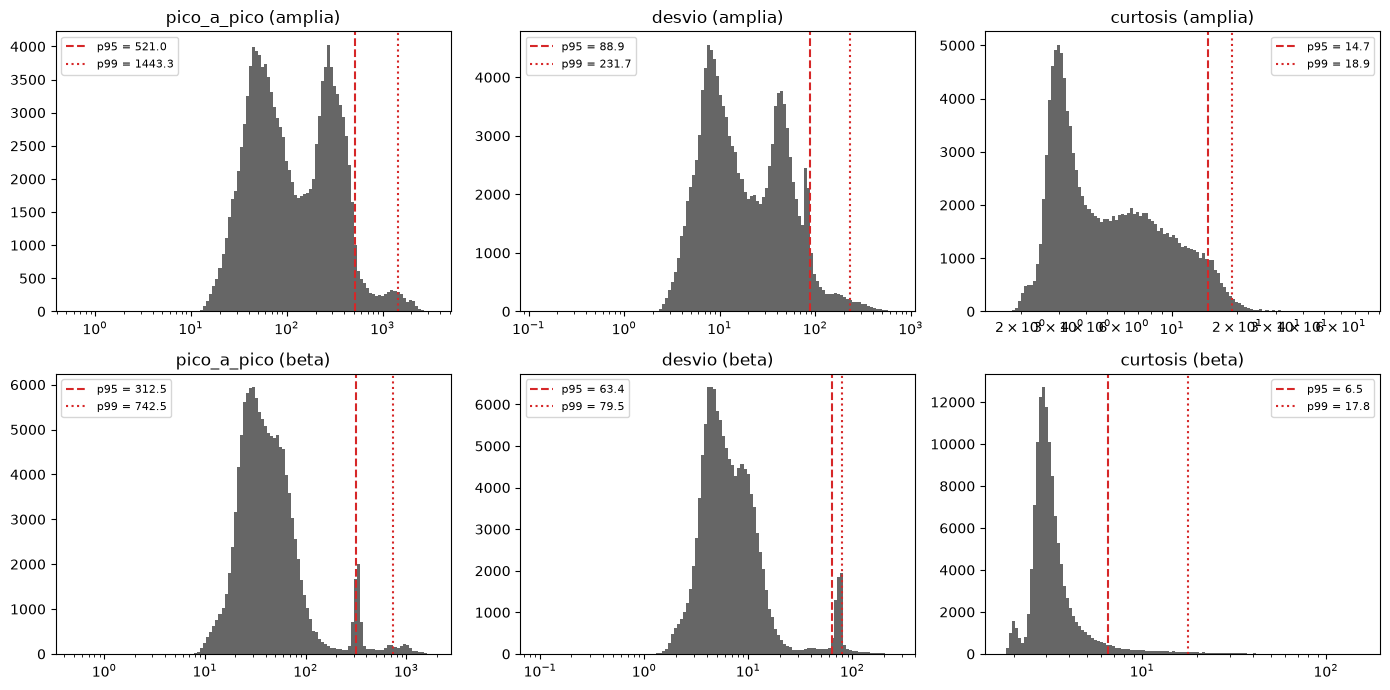

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(14, 7))
for fila, (nivel, tab) in zip(axs, tablas.items()):
    for ax, col in zip(fila, ['pico_a_pico', 'desvio', 'curtosis']):
        v = tab[col]
        ax.hist(v, bins=np.logspace(np.log10(v.min() + 1e-3), np.log10(v.max()), 120), color='0.4')
        for q, ls in ((0.95, '--'), (0.99, ':')):
            ax.axvline(v.quantile(q), color='C3', ls=ls, label=f'p{q * 100:.0f} = {v.quantile(q):.1f}')
        ax.set_xscale('log')
        ax.set_title(f'{col} ({nivel})')
        ax.legend(fontsize=8)
plt.tight_layout()

In [11]:
pct = [0.5, 0.75, 0.9, 0.95, 0.99]
pd.concat({k: t[['pico_a_pico', 'desvio', 'curtosis']].quantile(pct) for k, t in tablas.items()},
          axis=1).rename_axis('percentil').round(1)

amplia                        beta                
          pico_a_pico desvio curtosis pico_a_pico desvio curtosis
percentil                                                        
0.50            102.8   15.9      4.5        39.0    6.1      3.1
0.75            274.0   42.4      7.9        61.2    9.8      3.5
0.90            414.4   70.4     12.2        98.6   14.8      4.7
0.95            521.0   88.9     14.7       312.5   63.4      6.5
0.99           1443.3  231.7     18.9       742.5   79.5     17.8

In [12]:
print("Mediana por sujeto y canal (1-40 Hz):")
tablas['amplia'].groupby(['sujeto', 'canal'], sort=False)[['pico_a_pico', 'curtosis']].median().unstack('canal').reindex(sujetos.sujeto).round(1)

Mediana por sujeto y canal (1-40 Hz):


pico_a_pico                       curtosis                
canal          TP9    AF7    AF8    TP10      TP9  AF7  AF8  TP10
sujeto                                                           
A1           270.1   47.2   61.1   269.5      6.7  3.1  3.2   6.7
A2           430.0   71.6   93.2   441.2      9.5  3.6  3.3   9.6
A3            50.5   40.1   30.4    53.7      3.2  3.0  3.0   3.3
A4           162.3  601.2   58.6   150.9      5.1  2.7  3.4   5.6
A5            67.2   37.7   25.0    64.5      4.3  3.4  3.2   4.8
A6           242.7   56.4   31.3   251.1      8.4  6.7  3.2   8.4
A7           418.4   86.7  103.5   426.7      9.6  4.5  3.2   9.7
A8           227.8   38.8   41.1   225.1      7.5  3.4  3.4   7.8
A9           356.4   52.5  468.2  1339.5      9.8  4.3  2.7   5.1
A10          203.7   54.4   78.0   199.9      7.1  5.1  6.8   7.3
B1           327.8  380.8   61.8   318.7      9.2  2.2  3.1  10.1
B2            54.3   34.5   29.1    56.8      3.3  3.0  3.1   3.3
B3           223.2   27.7   24.4   230.2      7.8  3.5  3.2   7.8
B4            56.9   35.7   33.4    54.7      3.6  3.1  3.1   3.7
B5           228.7  368.8   50.2   231.1     10.8  4.2  3.5  10.8
B6           256.5   71.1   51.1   262.4      7.1  4.6  3.1   7.2
B7           164.4   93.7   94.9   170.3      6.3  3.2  3.1   6.1
B8           348.6   94.9  116.6   357.1      9.3  4.0  6.1   9.3
B9           258.8   53.9   54.1   265.9      7.6  3.3  3.4   7.6
B10          310.1   76.7   70.7   306.3      9.5  3.0  3.1   9.7

El pico a pico en 1–40 Hz es **bimodal**: un modo de épocas limpias (~50 µV) y otro de épocas con deflexiones de TP9/TP10 (~350 µV). En 13–40 Hz queda un solo modo (~35 µV) y grupos aislados de cientos de µV (los canales con picos angostos de la sección 4 y A9). El umbral de pico a pico se pone en el **valle** del histograma (en escala logarítmica, suavizado) entre los dos modos, calculado y no elegido a ojo:

In [13]:
def valle(v, lo, hi, bins=150, suavizado=5):
    # Mínimo del histograma de log10(v) (suavizado con una media móvil) entre lo y hi
    h, bordes = np.histogram(np.log10(v[v > 0]), bins=bins)
    h = np.convolve(h, np.ones(suavizado) / suavizado, mode='same')
    centros = 10 ** ((bordes[:-1] + bordes[1:]) / 2)
    m = (centros > lo) & (centros < hi)
    return centros[m][np.argmin(h[m])]

print(f"1-40 Hz: valle del pico a pico entre 60 y 300 µV: {valle(tablas['amplia'].pico_a_pico.to_numpy(), 60, 300):.0f} µV")

# 13-40 Hz: sin los canales con picos angostos (sección 4), dónde termina el modo principal
frac_ses = canales_ses.set_index(['sujeto', 'sesion', 'canal']).frac_picos_beta
b = tablas['beta']
sin_picos = b[frac_ses.reindex(pd.MultiIndex.from_frame(b[['sujeto', 'sesion', 'canal']])).to_numpy() <= 0.25]
print(f"13-40 Hz, canales sin picos angostos: percentil 95 = {sin_picos.pico_a_pico.quantile(0.95):.0f} µV; "
      f"superan 150 µV: {(sin_picos.pico_a_pico > 150).mean() * 100:.1f} % "
      f"({(sin_picos.query('sujeto != \'A9\'').pico_a_pico > 150).mean() * 100:.1f} % sin contar A9)")

1-40 Hz: valle del pico a pico entre 60 y 300 µV: 137 µV
13-40 Hz, canales sin picos angostos: percentil 95 = 105 µV; superan 150 µV: 2.8 % (1.4 % sin contar A9)


**Umbrales elegidos** (los mismos en las dos versiones):

| Criterio | Umbral | Justificación |
|---|---|---|
| Saturada | alguna muestra a ±1000 µV en la señal cruda, ±1 s | La Muse satura en ±1000 µV; el filtrado desparrama el escalón (pasa banda de 1 Hz y τ = 1,3 s del LMS). |
| Pico a pico | > 150 µV | En 1–40 Hz el valle entre los dos modos cae en ~140 µV (calculado arriba); el valle es ancho: entre 125 y 175 µV el porcentaje de épocas que supera el umbral va de 46 a 39 % (tabla de sensibilidad abajo), y el 72 % de las épocas que están en ese rango igual las rechaza otro criterio (curtosis, varianza o saturación). En 13–40 Hz no hay valle, pero el modo principal termina ahí: en los canales sin picos angostos el percentil 95 es ~105 µV y por encima de 150 µV queda menos del 3 % de las épocas, casi todas de A9. |
| Varianza | z robusto de log(varianza) > 3,5, por sujeto y canal | 3,5 es el valor habitual para el z-score robusto (Iglewicz y Hoaglin); por sujeto y canal porque la amplitud de cada electrodo seco depende de su contacto. |
| Curtosis | > 5 | En una época gaussiana de N muestras independientes el desvío de la curtosis estimada es √(24/N): 0,2 con N = 512. Las muestras del EEG filtrado están correlacionadas y el N efectivo es menor, pero aun con N = 100 el desvío es 0,5 y 5 queda a 4 desvíos de 3. Solo la superan épocas con eventos aislados (el "hombro" del histograma de 1–40 Hz). |
| Plana | desvío < 1 µV | Muy por debajo del percentil 5 (3–5 µV): electrodo sin contacto. |

In [14]:
UMBRALES = {nivel: dict(umbral_pp=150.0, umbral_z=3.5, umbral_curtosis=5.0, desvio_min=1.0)
            for nivel in ('amplia', 'beta')}
print("Sensibilidad: % de épocas-canal con pico a pico mayor que el umbral")
display(pd.DataFrame({u: {nivel: (t.pico_a_pico > u).mean() * 100 for nivel, t in tablas.items()}
                      for u in (100, 125, 150, 175, 200)}).round(1).rename_axis('umbral [µV] →'))

marcadas = {nivel: epocas.marcar_artefactos(tablas[nivel], por=('sujeto', 'canal'), **UMBRALES[nivel])
            for nivel in tablas}
for nivel, m in marcadas.items():
    print(f"{nivel}: {100 * (~m.valida).mean():.1f} % de épocas-canal rechazadas")
pd.concat({nivel: m.motivo.replace('', 'válida').value_counts(normalize=True) * 100
           for nivel, m in marcadas.items()}, axis=1).round(1).rename_axis('motivo (%)')

Sensibilidad: % de épocas-canal con pico a pico mayor que el umbral


,100,125,150,175,200
umbral [µV] →,,,,,
amplia,50.7,45.8,42.3,39.3,36.4
beta,9.8,7.8,7.1,6.7,6.5


amplia: 55.0 % de épocas-canal rechazadas
beta: 13.9 % de épocas-canal rechazadas


,amplia,beta
motivo (%),,
válida,45.0,86.1
pico_a_pico,40.0,5.0
curtosis,12.1,5.5
saturada,2.5,2.5
varianza,0.5,1.0
plana,0.0,0.0


Ejemplos de épocas rechazadas por cada motivo (1–40 Hz), sobre B1:

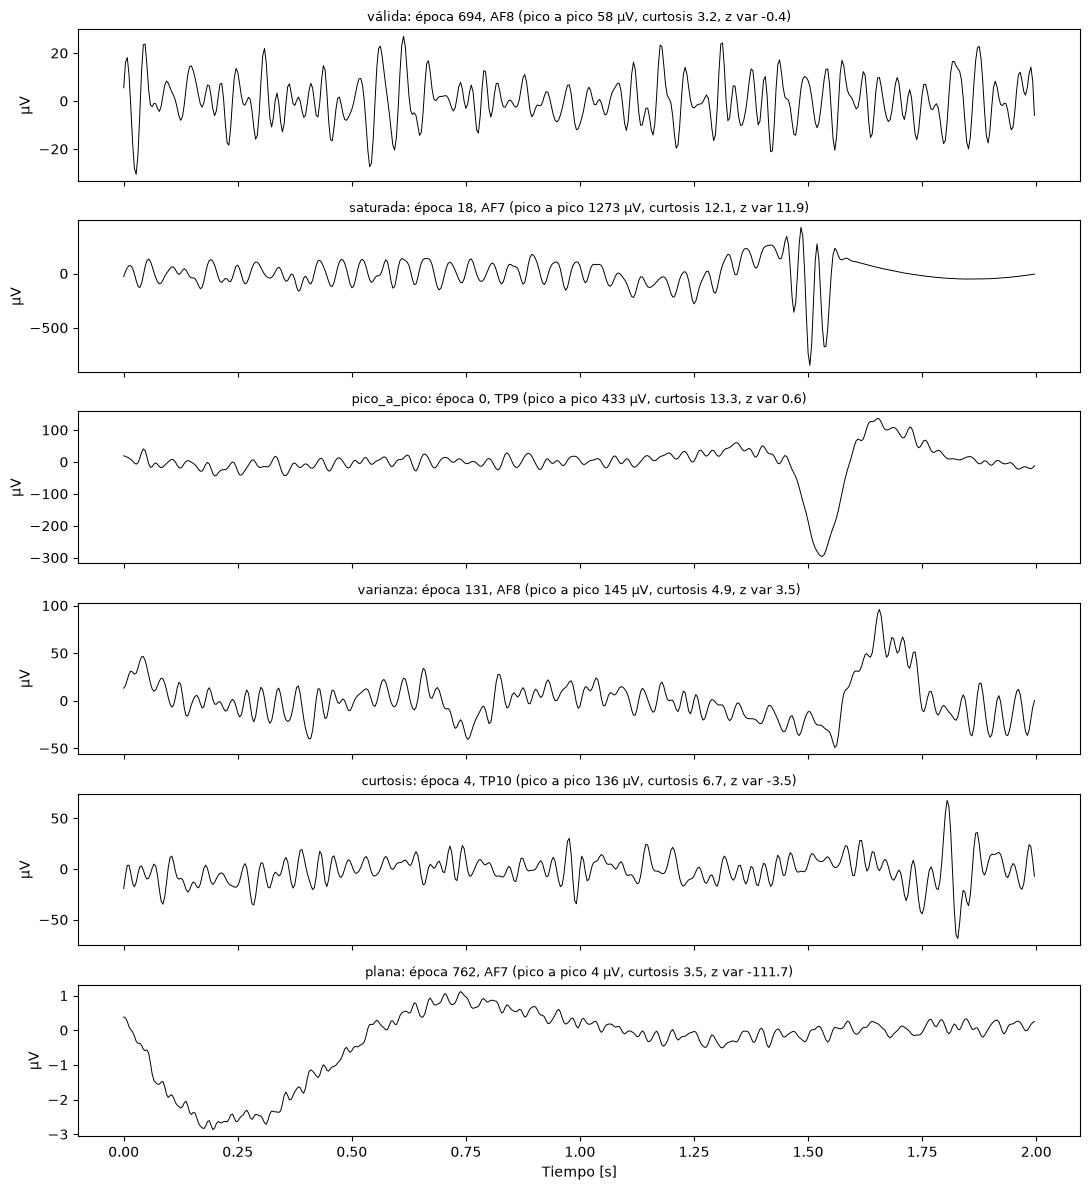

In [15]:
m_b1 = marcadas['amplia'].query("sujeto == 'B1'")
motivos = [mo for mo in epocas.MOTIVOS if (m_b1.motivo == mo).any()]
fig, axs = plt.subplots(len(motivos) + 1, 1, figsize=(11, 2 * (len(motivos) + 1)), sharex=True)
tt = np.arange(ep_b1.shape[1]) / FS
for ax, mo in zip(axs, ['válida'] + motivos):
    fila = m_b1[m_b1.valida].iloc[len(m_b1[m_b1.valida]) // 2] if mo == 'válida' else m_b1[m_b1.motivo == mo].iloc[0]
    ax.plot(tt, ep_b1[fila.epoca, :, CANALES.index(fila.canal)], lw=0.7, color='k')
    ax.set_title(f'{mo}: época {fila.epoca}, {fila.canal} (pico a pico {fila.pico_a_pico:.0f} µV, '
                 f'curtosis {fila.curtosis:.1f}, z var {fila.z_varianza:.1f})', fontsize=9)
    ax.set_ylabel('µV')
axs[-1].set_xlabel('Tiempo [s]')
plt.tight_layout()

## 4. Criterio a nivel canal: picos angostos dentro de beta

En la Parte 1 (sección 5) aparecieron picos angostos en **21,3 Hz** y **24 Hz** en algunos canales, de hasta 1000 veces el fondo. Una posible explicación, que no se puede verificar con estos datos: la Muse transmite el EEG en paquetes de 12 muestras, y 256 Hz / 12 = 21,33 Hz.

Estos picos no son actividad cerebral y caen dentro de beta, pero los criterios por época no los detectan: la oscilación es estable (no cambia la varianza entre épocas) y casi senoidal (curtosis baja). Para cada sesión y canal se mide **qué fracción de la potencia beta aportan los picos** (`epocas.fraccion_picos_beta`): el exceso de potencia en f₀ ± 1 Hz respecto del fondo, sumado en las dos frecuencias, sobre la potencia en 13–30 Hz.

In [16]:
UMBRAL_FRAC = 0.25
frac = canales_ses.pivot_table(index='sujeto', columns='canal', values='frac_picos_beta', aggfunc='max')
frac = frac.reindex(index=sujetos.sujeto, columns=CANALES)
print("Fracción de la potencia beta que aportan los picos de 21,3 y 24 Hz (máximo entre sesiones):")
(frac * 100).round(1)

Fracción de la potencia beta que aportan los picos de 21,3 y 24 Hz (máximo entre sesiones):


canal,TP9,AF7,AF8,TP10
sujeto,,,,
A1,1.9,3.1,5.1,4.1
A2,11.1,5.1,7.1,9.9
A3,0.4,7.9,6.2,11.0
A4,3.5,82.0,3.8,5.8
A5,2.7,11.3,4.3,10.0
A6,1.4,12.2,6.0,8.7
A7,2.0,7.4,9.1,2.2
A8,8.2,6.3,8.7,2.2
A9,2.3,7.1,81.0,1.1


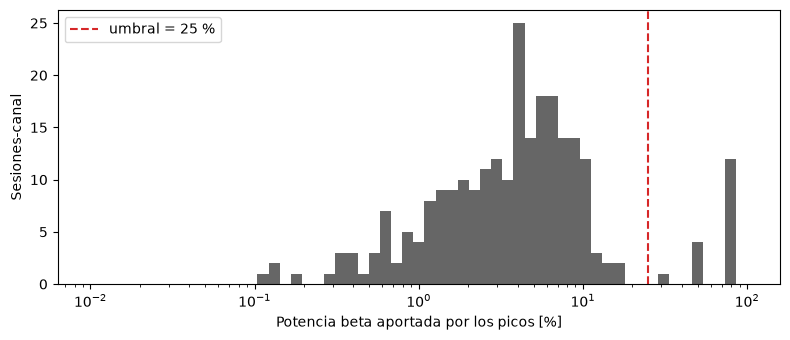

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.5))
v = canales_ses.frac_picos_beta * 100
ax.hist(v, bins=np.logspace(-2, 2, 60), color='0.4')
ax.set_xscale('log')
ax.axvline(UMBRAL_FRAC * 100, color='C3', ls='--', label=f'umbral = {UMBRAL_FRAC * 100:g} %')
ax.set_xlabel('Potencia beta aportada por los picos [%]')
ax.set_ylabel('Sesiones-canal')
ax.legend()
plt.tight_layout()

La distribución es **bimodal**: en las sesiones-canal sin picos la fracción va de 0 a ~16 % (el método da valores chicos aun sin pico, porque el espectro de fondo no es plano), y en las que tienen picos va de ~30 a 85 %. **No hay ningún caso entre 17 y 30 %**, así que el umbral de **25 %** separa los dos grupos sin ambigüedad.

Los canales excluidos son los que ya se habían identificado en la Parte 1: **A4-AF7, A9-AF8, B1-AF7, B1-TP9 y B5-AF7**, en todas sus sesiones. En esos canales los picos aportan entre la mitad y el 85 % de la potencia beta: estimar beta ahí sería medir el artefacto.

In [18]:
canales_ses = epocas.marcar_canales(canales_ses, UMBRAL_FRAC)
print("Canales que no se usan (por sesión):")
canales_ses[~canales_ses.usar].groupby(['sujeto', 'canal'], sort=False).condicion.agg(list)

Canales que no se usan (por sesión):


sujeto  canal
A4      AF7      [sin_musica, relajante, estimulante, ia]
A9      AF8      [sin_musica, relajante, estimulante, ia]
B1      TP9                        [basal, perfume, cafe]
        AF7                        [basal, perfume, cafe]
B5      AF7                        [basal, perfume, cafe]
Name: condicion, dtype: object

## 5. Calidad resultante

Una época-canal se usa si es válida **y** el canal se usa en esa sesión. Porcentaje de épocas usables por sujeto y canal, en las dos versiones:

In [19]:
usar = canales_ses.set_index(['sujeto', 'sesion', 'canal']).usar
final = {}
for nivel, m in marcadas.items():
    u = usar.reindex(pd.MultiIndex.from_frame(m[['sujeto', 'sesion', 'canal']])).to_numpy()
    final[nivel] = m.assign(canal_ok=u, usable=m.valida & u)

calidad = pd.concat({nivel: (f.groupby(['sujeto', 'canal'], sort=False).usable.mean() * 100).unstack('canal')
                     for nivel, f in final.items()}, axis=1).reindex(sujetos.sujeto)
calidad.round(0)

amplia                    beta                    
canal     TP9   AF7   AF8  TP10   TP9    AF7    AF8  TP10
sujeto                                                   
A1        9.0  86.0  88.0  10.0  93.0   92.0   93.0  93.0
A2        6.0  76.0  81.0   5.0  94.0   97.0   99.0  94.0
A3       77.0  88.0  88.0  77.0  89.0   99.0   98.0  89.0
A4       24.0   0.0  83.0  24.0  87.0    0.0   86.0  86.0
A5       53.0  71.0  82.0  51.0  94.0   97.0   95.0  92.0
A6       13.0  31.0  90.0  19.0  80.0   97.0   97.0  88.0
A7        1.0  59.0  84.0   1.0  62.0   94.0   93.0  59.0
A8        3.0  88.0  86.0   2.0  87.0   97.0   96.0  85.0
A9        6.0  65.0   0.0   0.0  78.0   95.0    0.0   3.0
A10      13.0  47.0  26.0  14.0  78.0   96.0   96.0  81.0
B1        0.0   0.0  92.0  15.0   0.0    0.0   99.0  96.0
B2       73.0  91.0  77.0  70.0  89.0   99.0   98.0  87.0
B3       10.0  76.0  80.0  11.0  83.0   85.0   88.0  84.0
B4       61.0  92.0  92.0  61.0  95.0   96.0   95.0  95.0
B5        2.0   0.0  88.0   2.0  92.0    0.0   97.0  96.0
B6        5.0  56.0  87.0   5.0  88.0   92.0   93.0  90.0
B7       10.0  87.0  92.0  11.0  94.0   93.0   96.0  95.0
B8        2.0  72.0  19.0   2.0  80.0  100.0  100.0  82.0
B9       14.0  92.0  91.0  12.0  94.0   97.0   97.0  95.0
B10      15.0  96.0  94.0  15.0  96.0   99.0   99.0  93.0

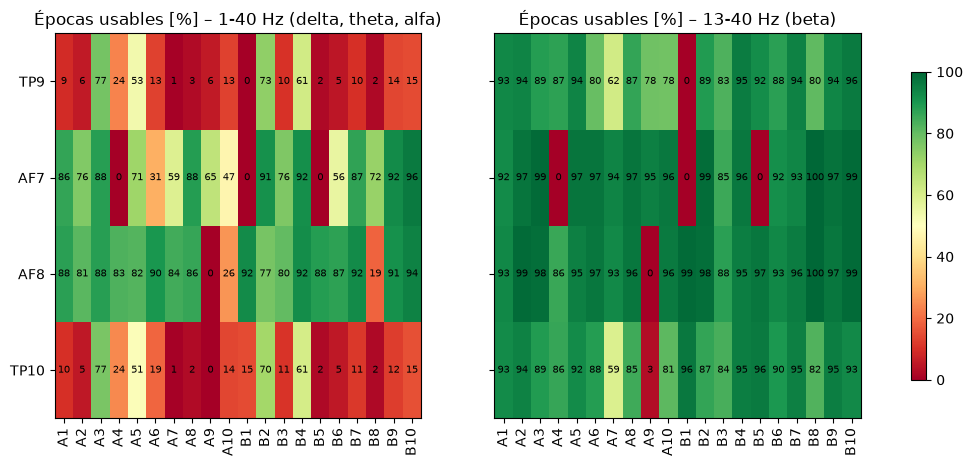

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, nivel in zip(axs, final):
    d = calidad[nivel][CANALES]
    im = ax.imshow(d.to_numpy().T, aspect='auto', cmap='RdYlGn', vmin=0, vmax=100)
    ax.set_xticks(range(len(d)), d.index, rotation=90)
    ax.set_yticks(range(len(CANALES)), CANALES)
    for i in range(d.shape[0]):
        for j in range(d.shape[1]):
            ax.text(i, j, f'{d.iat[i, j]:.0f}', ha='center', va='center', fontsize=7)
    ax.set_title(f'Épocas usables [%] – {"1-40 Hz (delta, theta, alfa)" if nivel == "amplia" else "13-40 Hz (beta)"}')
fig.colorbar(im, ax=axs, shrink=0.8)

### 5.1 ¿El rechazo depende de la condición o de la carga?

Si se descartaran más épocas en 3-back que en 1-back (por ejemplo, porque el sujeto se mueve más cuando la tarea es difícil), la comparación de la Parte 5 quedaría sesgada. Se compara el porcentaje de épocas usables por tipo de tramo y por condición:

In [21]:
pd.concat({nivel: (f.groupby('tipo').usable.mean() * 100) for nivel, f in final.items()}, axis=1).round(1)

,amplia,beta
tipo,,
1-back,46.7,86.6
3-back,46.3,86.0
pausa,39.3,79.2


In [22]:
from scipy import stats
for nivel, f in final.items():
    d = (f[f.tipo != 'pausa'].groupby(['sujeto', 'canal', 'tipo']).usable.mean().unstack('tipo').dropna())
    w = stats.wilcoxon(d['1-back'], d['3-back'])
    print(f"{nivel}: usables 1-back {d['1-back'].median() * 100:.1f} %, 3-back {d['3-back'].median() * 100:.1f} % "
          f"(mediana por sujeto-canal); Wilcoxon p = {w.pvalue:.2g}")

amplia: usables 1-back 47.8 %, 3-back 49.1 % (mediana por sujeto-canal); Wilcoxon p = 0.48
beta: usables 1-back 95.5 %, 3-back 96.2 % (mediana por sujeto-canal); Wilcoxon p = 0.36


In [23]:
pd.concat({nivel: (f.groupby('condicion', sort=False).usable.mean() * 100) for nivel, f in final.items()},
          axis=1).round(1)

,amplia,beta
condicion,,
sin_musica,44.1,83.3
relajante,43.1,83.8
estimulante,42.3,82.0
ia,43.2,84.1
basal,48.1,86.5
perfume,45.1,85.3
cafe,47.2,87.0


El porcentaje de épocas usables es prácticamente igual en 1-back y 3-back, en las dos versiones, y la diferencia por sujeto y canal no es significativa (Wilcoxon). Tampoco cambia mucho entre condiciones (diferencias de pocos puntos). **El rechazo no favorece a ninguna condición**: la comparación de la Parte 5 no queda sesgada por qué épocas se descartan.

Las pausas pierden algo más de épocas que los bloques: es esperable, porque en el reposo el sujeto parpadea y se acomoda más.

### 5.2 Regla para usar un canal en un sujeto

Con pocas épocas la PSD promedio es poco confiable y además puede estar dominada por las épocas "menos malas" de un canal malo. Se usa un canal de un sujeto en una banda si conserva **al menos el 50 %** de sus épocas de tarea en **cada** sesión (así todas las condiciones se pueden comparar dentro del sujeto).

In [24]:
MIN_USABLES = 0.5
cobertura = {}
for nivel, f in final.items():
    d = f[f.tipo != 'pausa'].groupby(['sujeto', 'canal', 'sesion']).usable.mean().groupby(['sujeto', 'canal']).min()
    cobertura[nivel] = (d >= MIN_USABLES).unstack('canal').reindex(index=sujetos.sujeto, columns=CANALES)
pd.concat(cobertura, axis=1).replace({True: '✓', False: '✗'})

amplia              beta             
canal     TP9 AF7 AF8 TP10  TP9 AF7 AF8 TP10
sujeto                                      
A1          ✗   ✓   ✓    ✗    ✓   ✓   ✓    ✓
A2          ✗   ✓   ✓    ✗    ✓   ✓   ✓    ✓
A3          ✓   ✓   ✓    ✓    ✓   ✓   ✓    ✓
A4          ✗   ✗   ✓    ✗    ✓   ✗   ✓    ✓
A5          ✗   ✓   ✓    ✗    ✓   ✓   ✓    ✓
A6          ✗   ✗   ✓    ✗    ✓   ✓   ✓    ✓
A7          ✗   ✗   ✓    ✗    ✗   ✓   ✓    ✗
A8          ✗   ✓   ✓    ✗    ✓   ✓   ✓    ✓
A9          ✗   ✗   ✗    ✗    ✓   ✓   ✗    ✗
A10         ✗   ✗   ✗    ✗    ✓   ✓   ✓    ✓
B1          ✗   ✗   ✓    ✗    ✗   ✗   ✓    ✓
B2          ✓   ✓   ✓    ✓    ✓   ✓   ✓    ✓
B3          ✗   ✓   ✓    ✗    ✓   ✓   ✓    ✓
B4          ✓   ✓   ✓    ✓    ✓   ✓   ✓    ✓
B5          ✗   ✗   ✓    ✗    ✓   ✗   ✓    ✓
B6          ✗   ✗   ✓    ✗    ✓   ✓   ✓    ✓
B7          ✗   ✓   ✓    ✗    ✓   ✓   ✓    ✓
B8          ✗   ✗   ✗    ✗    ✓   ✓   ✓    ✓
B9          ✗   ✓   ✓    ✗    ✓   ✓   ✓    ✓
B10         ✗   ✓   ✓    ✗    ✓   ✓   ✓    ✓

In [25]:
for nivel, c in cobertura.items():
    print(f"{nivel}: canales usables por sujeto: {c.sum(axis=1).value_counts().sort_index(ascending=False).to_dict()}; "
          f"sujetos por canal: {c.sum().to_dict()}")

amplia: canales usables por sujeto: {4: 3, 2: 8, 1: 6, 0: 3}; sujetos por canal: {'TP9': 3, 'AF7': 11, 'AF8': 17, 'TP10': 3}
beta: canales usables por sujeto: {4: 15, 3: 2, 2: 3}; sujetos por canal: {'TP9': 18, 'AF7': 17, 'AF8': 19, 'TP10': 18}


## 6. Resultado para la Parte 3

Se guarda en `outputs/` una tabla con una fila por época y canal (sujeto, sesión, condición, bloque, tipo, época, canal, `usable` y `usable_beta`) y la tabla de canales por sujeto. La Parte 3 vuelve a generar las épocas con `epocas.epocas_sujeto` (es determinístico) y se queda con las marcadas como usables.

In [26]:
cfg['OUTPUT_DIR'].mkdir(exist_ok=True)
claves = ['sujeto', 'sesion', 'condicion', 'bloque', 'tipo', 'epoca', 't_centro', 'canal']
salida = final['amplia'][claves + ['usable']].merge(
    final['beta'][claves + ['usable']].rename(columns={'usable': 'usable_beta'}), on=claves)
salida.to_csv(cfg['OUTPUT_DIR'] / 'epocas_usables.csv', index=False)
pd.concat(cobertura, axis=1).to_csv(cfg['OUTPUT_DIR'] / 'canales_por_sujeto.csv')
print(f"{len(salida)} filas -> {cfg['OUTPUT_DIR'] / 'epocas_usables.csv'}")

126232 filas -> /Users/luciaburman/Library/Application Support/Claude/scratch-workspaces/109987ac-38e2-45e0-b31a-d28319d346d2/fb3b73bb-f70a-453c-8337-cc932c2b4ab0/scratch-2026-11-02-da9a74/repo/outputs/epocas_usables.csv


## 7. Conclusiones

1. **Épocas:** de 2 s, alineadas con el primer estímulo de cada bloque, así que cada época es un ensayo (estímulo + fijación). Se recortan los bloques (21 épocas cada uno) y las pausas (unas 7). En total, unas 31.500 épocas en los 20 sujetos.
2. **Saturación:** se marca sobre la señal cruda (±1000 µV) y se ensancha 1 s para cada lado, porque el filtrado desparrama el escalón. Afecta al 2,5 % de las épocas-canal.
3. **Deflexiones en TP9/TP10:** en 16 de los 20 sujetos (todos menos A3, A5, B2 y B4), TP9 y TP10 tienen deflexiones de cientos de µV, simultáneas en los dos canales, en la mayoría de las épocas, no ligadas al estímulo. Son compatibles con parpadeos vistos a través de la referencia Fpz. Multiplican la potencia de delta y theta decenas de veces pero **no cambian la de beta**.
4. **Por eso el rechazo tiene dos niveles:** los mismos criterios (saturación, pico a pico > 150 µV, z robusto de log-varianza > 3,5, curtosis > 5, desvío < 1 µV) se calculan sobre la señal de 1–40 Hz (`usable`, para delta, theta y alfa) y sobre la de 13–40 Hz (`usable_beta`, para beta). Los umbrales salen de las distribuciones (valle del pico a pico, percentiles, desvío de la curtosis gaussiana).
5. **Picos angostos de 21,3 y 24 Hz:** se mide qué fracción de la potencia beta aportan. La distribución es bimodal (≤ 16 % o ≥ 30 %) y con un umbral de 25 % se excluyen A4-AF7, A9-AF8, B1-AF7, B1-TP9 y B5-AF7.
6. **Resultado:**
   - **Beta:** se conserva el 86 % de las épocas. Con la regla de al menos 50 % de épocas usables en cada sesión, **15 de los 20 sujetos tienen los 4 canales** y cada canal se puede usar en 17 a 19 sujetos.
   - **Delta, theta y alfa:** se conserva el 45 % de las épocas. TP9 y TP10 sirven solo en 3 sujetos (A3, B2 y B4); AF8 en 17 y AF7 en 11. **Esas bandas se analizan sobre los canales frontales.**
   - **A9**, el sujeto que analiza el artículo, tiene canales muy malos: en beta solo se usan TP9 y AF7, y en las bandas lentas ninguno. Hay que tenerlo en cuenta al comparar con el artículo, que usa los temporales.
7. **Sin sesgo:** el porcentaje de épocas usables no difiere entre 1-back y 3-back (Wilcoxon p > 0,3 en las dos versiones) ni cambia mucho entre condiciones.
8. **Para la Parte 3:** `outputs/epocas_usables.csv` (una fila por época y canal, con `usable` y `usable_beta`) y `outputs/canales_por_sujeto.csv`. Las épocas se regeneran con `epocas.epocas_sujeto`, que es determinístico.